# Project 10: Open-Domain Question Answering – From Lexical Retrieval to RAG

| | |
|---|---|
| **Name** | Mehul Mathur |
| **Roll No.** | 23CS30033 |
| **Group** | 28 |
| **Project** | 10 |
| **Dataset** | rag-mini-wikipedia |

**Pipeline overview**
- **Task 1 (Baseline):** BM25 retrieval (`rank_bm25`, k1 = 1.5, b = 0.75) + rule-based extractive answering (best-overlap sentence → longest noun phrase / number span).
- **Task 2 (Paper reproduction, RAG – Lewis et al. 2020):** dense retrieval (`all-MiniLM-L6-v2` + FAISS flat, cosine) + LLM generation from top-5 passages.
- **Task 3 (Combine & improve):** Reciprocal Rank Fusion (c = 60) of BM25 + dense rankings, plus a lexical-overlap groundedness check on generated answers.

**Metrics:** Exact Match (EM), token-F1, recall@k (k ∈ {1, 3, 5, 10}), groundedness-check accuracy.

**Runtime:** Colab with a **T4 GPU** (Runtime → Change runtime type → T4 GPU). Run all cells top to bottom (~20 min end to end on a T4; LLM generation ≈ 13 min of that). Set `N_QUESTIONS` in the config cell to a small number for a quick test run.

**Pretrained checkpoints used (all from the Hugging Face Hub)**
- Dense retriever: [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- Generator: [`Qwen/Qwen2.5-3B-Instruct`](https://huggingface.co/Qwen/Qwen2.5-3B-Instruct) (open instruction-tuned LLM, Apache-2.0)
- spaCy pipeline: [`en_core_web_sm`](https://github.com/explosion/spacy-models) (sentence splitting, noun chunks, number entities)

**Dataset:** [`rag-datasets/rag-mini-wikipedia`](https://huggingface.co/datasets/rag-datasets/rag-mini-wikipedia) – `text-corpus` (passage index) and `question-answer` (918 QA pairs). It is downloaded automatically by `datasets.load_dataset` below; no manual preparation is needed.

**Seed:** `SEED = 42` for Python, NumPy and PyTorch. Generation is greedy (temperature = 0), so outputs are deterministic for a fixed environment.

## 0. Setup

In [1]:
# install packages that are not preinstalled on Colab (versions pinned)
!pip install -q rank_bm25==0.2.2 faiss-cpu==1.11.0
!python -m spacy download en_core_web_sm -q

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os, re, json, time, random, string, collections, importlib.metadata as md_
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import spacy
import faiss
from rank_bm25 import BM25Okapi
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM

# config
SEED = 42
TOP_K = 5                     # passages used for answering
K_LIST = [1, 3, 5, 10]        # recall@k cut-offs
DEPTH = 100                   # ranking depth kept per retriever (used by RRF)
BM25_K1, BM25_B = 1.5, 0.75
RRF_C = 60
DENSE_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
LLM_NAME = "Qwen/Qwen2.5-3B-Instruct"
MAX_PASSAGE_TOKENS = 200
MAX_NEW_TOKENS = 64
GEN_BATCH = 16
GROUND_TAU = 0.5              # fixed before looking at results
CORRECT_F1 = 0.5              # answer counted correct for groundedness analysis if F1 >= this
N_QUESTIONS = None            # e.g. 50 for a quick debug run, None = all 918
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

# plot style and fixed colors per system
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3, "font.size": 10})
C = {"BM25": "#2a78d6", "Dense": "#eb6834", "Hybrid (RRF)": "#1baf7a", "Closed-book": "#eda100",
     "correct": "#0ca30c", "incorrect": "#d03b3b"}
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu130


In [3]:
# record exact package versions used (requirements.txt for reproducibility)
pkgs = ["torch", "transformers", "sentence-transformers", "datasets", "faiss-cpu", "rank_bm25",
        "spacy", "scikit-learn", "numpy", "pandas", "matplotlib", "accelerate"]
vers = {}
for p in pkgs:
    try: vers[p] = md_.version(p)
    except md_.PackageNotFoundError: pass
with open(os.path.join(OUT_DIR, "requirements.txt"), "w") as f:
    f.write("\n".join(f"{k}=={v}" for k, v in vers.items()) + "\n")
print(pd.Series(vers).to_string())

torch                    2.14.1+cu130
transformers                   5.22.1
sentence-transformers           5.7.0
datasets                        4.8.5
faiss-cpu                      1.11.0
rank_bm25                       0.2.2
spacy                          3.8.18
scikit-learn                    1.6.1
numpy                           2.4.6
pandas                          2.2.3
matplotlib                     3.10.0
accelerate                     1.15.0


### 0.1 Load dataset

In [4]:
corpus_dd = load_dataset("rag-datasets/rag-mini-wikipedia", "text-corpus")
qa_dd = load_dataset("rag-datasets/rag-mini-wikipedia", "question-answer")
corpus_df = corpus_dd[list(corpus_dd.keys())[0]].to_pandas()
qa_df = qa_dd[list(qa_dd.keys())[0]].to_pandas()

# passage index (built once, reused by all three tasks)
corpus_df["passage"] = corpus_df["passage"].astype(str).str.strip()
corpus_df = corpus_df[corpus_df["passage"].str.len() > 0].reset_index(drop=True)
PASSAGES = corpus_df["passage"].tolist()

qa_df["question"] = qa_df["question"].astype(str).str.strip()
qa_df["answer"] = qa_df["answer"].astype(str).str.strip()
qa_df = qa_df[(qa_df["question"].str.len() > 0) & (qa_df["answer"].str.len() > 0)].reset_index(drop=True)
if N_QUESTIONS:
    qa_df = qa_df.sample(n=N_QUESTIONS, random_state=SEED).reset_index(drop=True)
QUESTIONS, ANSWERS = qa_df["question"].tolist(), qa_df["answer"].tolist()
print(f"{len(PASSAGES)} passages | {len(QUESTIONS)} questions")
qa_df.head()

README.md:   0%|          | 0.00/719 [00:00<?, ?B/s]

data/passages.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B /  797kB            

data/passages.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating passages split:   0%|          | 0/3200 [00:00<?, ? examples/s]

data/test.parquet/part.0.parquet: reconstructing file:   0%|          |  0.00B / 54.4kB            

data/test.parquet/part.0.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/918 [00:00<?, ? examples/s]

3200 passages | 918 questions


,question,answer,id
0,Was Abraham Lincoln the sixteenth President of...,yes,0
1,Did Lincoln sign the National Banking Act of 1...,yes,2
2,Did his mother die of pneumonia?,no,4
3,How many long was Lincoln's formal education?,18 months,6
4,When did Lincoln begin his political career?,1832,8


### 0.2 Shared utilities (normalisation, EM/F1, recall@k)

In [5]:
def normalize_answer(s):
    # SQuAD-style: lowercase, drop punctuation, articles and extra whitespace
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    common = collections.Counter(p) & collections.Counter(g)
    same = sum(common.values())
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    if same == 0:
        return 0.0
    prec, rec = same / len(p), same / len(g)
    return 2 * prec * rec / (prec + rec)

def is_yes_no(ans):
    return normalize_answer(ans) in {"yes", "no"}

def question_type(q, a):
    if is_yes_no(a): return "yes/no"
    w = q.lower().split()
    for t in ["who", "what", "when", "where", "which", "how", "why"]:
        if t in w[:3]: return t
    return "other"

def answer_in_passage(ans, passage):
    na, npas = normalize_answer(ans), normalize_answer(passage)
    return len(na) > 0 and f" {na} " in f" {npas} "

qa_df["qtype"] = [question_type(q, a) for q, a in zip(QUESTIONS, ANSWERS)]
SPAN_MASK = ~qa_df["qtype"].eq("yes/no").values   # recall@k is only defined for span answers

def recall_at_k(ranked_ids, ks=K_LIST):
    # fraction of span-answer questions whose gold answer string appears in any of the top-k passages
    out = {}
    for k in ks:
        hits = [any(answer_in_passage(ANSWERS[i], PASSAGES[p]) for p in ranked_ids[i][:k])
                for i in range(len(QUESTIONS)) if SPAN_MASK[i]]
        out[f"R@{k}"] = 100 * np.mean(hits)
    return out

def qa_scores(preds):
    em = np.array([exact_match(p, g) for p, g in zip(preds, ANSWERS)])
    f1 = np.array([f1_score(p, g) for p, g in zip(preds, ANSWERS)])
    return {"EM": 100 * em.mean(), "F1": 100 * f1.mean(),
            "EM (span)": 100 * em[SPAN_MASK].mean(), "F1 (span)": 100 * f1[SPAN_MASK].mean(),
            "EM (yes/no)": 100 * em[~SPAN_MASK].mean() if (~SPAN_MASK).any() else np.nan}, em, f1

print(f"span-answer questions: {SPAN_MASK.sum()} | yes/no questions: {(~SPAN_MASK).sum()}")

span-answer questions: 508 | yes/no questions: 410


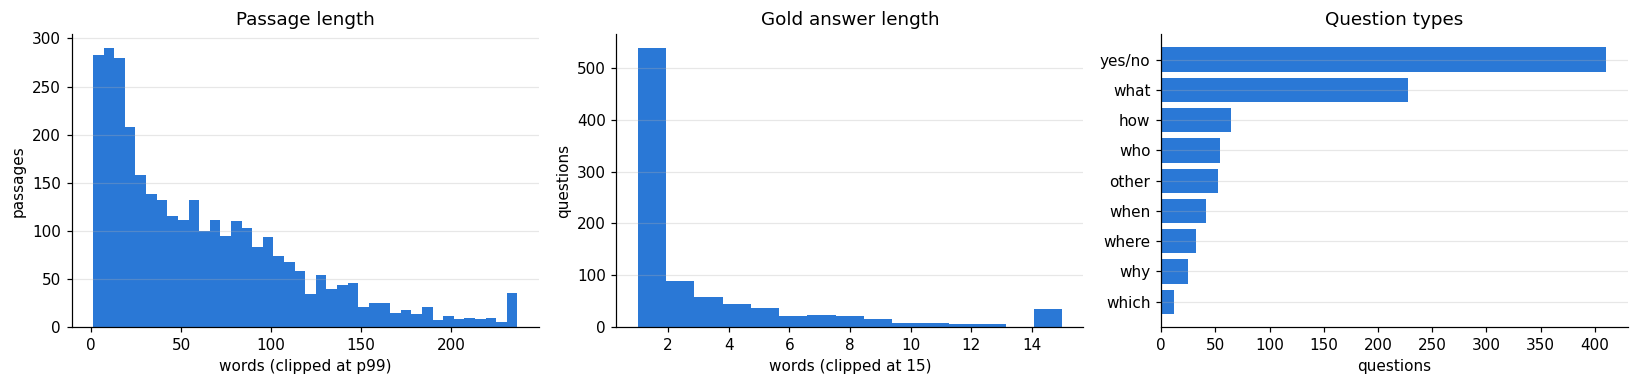

In [6]:
# dataset overview plots
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
plen = corpus_df["passage"].str.split().str.len()
ax[0].hist(plen.clip(upper=plen.quantile(0.99)), bins=40, color=C["BM25"])
ax[0].set(title="Passage length", xlabel="words (clipped at p99)", ylabel="passages")
alen = qa_df["answer"].str.split().str.len()
ax[1].hist(alen.clip(upper=15), bins=15, color=C["BM25"])
ax[1].set(title="Gold answer length", xlabel="words (clipped at 15)", ylabel="questions")
qt = qa_df["qtype"].value_counts()
ax[2].barh(qt.index[::-1], qt.values[::-1], color=C["BM25"])
ax[2].set(title="Question types", xlabel="questions")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/dataset_overview.png", bbox_inches="tight"); plt.show()

## Task 1 — Baseline: Classical Lexical Retrieve-and-Extract

1. Index the provided passage corpus directly with BM25 (`rank_bm25.BM25Okapi`, k1 = 1.5, b = 0.75). Tokenisation: lowercase, `\w+` tokens, English stop-words removed.
2. Retrieve top-k passages (top-5 used for answering, top-10 for recall@k).
3. Answer by extraction (no generation): in the top-1 passage pick the sentence with highest lexical overlap with the question, then return the longest noun phrase or number span from it.
4. Evaluate EM/F1 and recall@k.

### 1.1 BM25 retrieval

In [7]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
STOP = set(ENGLISH_STOP_WORDS)

def tokenize(text):
    return [t for t in re.findall(r"\w+", text.lower()) if t not in STOP]

t0 = time.time()
bm25 = BM25Okapi([tokenize(p) for p in PASSAGES], k1=BM25_K1, b=BM25_B)
bm25_ranked = []
for q in QUESTIONS:
    scores = bm25.get_scores(tokenize(q))
    bm25_ranked.append(np.argsort(-scores, kind="stable")[:DEPTH].tolist())
print(f"BM25 index + retrieval: {time.time() - t0:.1f}s")
recall_bm25 = recall_at_k(bm25_ranked)
recall_bm25

BM25 index + retrieval: 8.1s


{'R@1': np.float64(47.83464566929133),
 'R@3': np.float64(56.889763779527556),
 'R@5': np.float64(60.23622047244095),
 'R@10': np.float64(62.79527559055118)}

### 1.2 Extractive answering (sentence overlap → longest noun phrase / number span)

In [8]:
nlp = spacy.load("en_core_web_sm", disable=["lemmatizer"])
NUM_ENTS = {"DATE", "TIME", "CARDINAL", "ORDINAL", "QUANTITY", "MONEY", "PERCENT"}
_doc_cache = {}

def get_doc(pid):
    if pid not in _doc_cache:
        _doc_cache[pid] = nlp(PASSAGES[pid])
    return _doc_cache[pid]

def best_sentence(question, doc):
    q = set(tokenize(question))
    sents = list(doc.sents) or [doc[:]]
    overlaps = [len(q & set(tokenize(s.text))) for s in sents]
    return sents[int(np.argmax(overlaps))]

def candidate_spans(sent):
    cands = [nc for nc in sent.noun_chunks]
    run = []
    for tok in list(sent) + [None]:
        if tok is not None and (tok.like_num or tok.ent_type_ in NUM_ENTS):
            run.append(tok)
        elif run:
            cands.append(sent.doc[run[0].i: run[-1].i + 1]); run = []
    return cands

def extract_answer(question, pid, q_filter=False):
    sent = best_sentence(question, get_doc(pid))
    cands = candidate_spans(sent)
    if q_filter:
        # variant: drop spans whose content words all already appear in the question
        q = set(tokenize(question))
        cands = [c for c in cands if not set(tokenize(c.text)) <= q] or cands
    if not cands:
        return sent.text
    return max(cands, key=lambda c: (len(c), -c.start)).text   # longest, earliest on ties

def run_extractive(ranked, q_filter=False):
    pids = sorted({r[0] for r in ranked})
    for pid, doc in zip(pids, nlp.pipe([PASSAGES[p] for p in pids], batch_size=64)):
        _doc_cache.setdefault(pid, doc)
    return [extract_answer(q, r[0], q_filter) for q, r in zip(QUESTIONS, ranked)]

t0 = time.time()
pred_t1 = run_extractive(bm25_ranked)                     # exactly as specified
pred_t1_qf = run_extractive(bm25_ranked, q_filter=True)   # + question-word filter
print(f"extraction: {time.time() - t0:.1f}s")

extraction: 24.3s


### 1.3 Task 1 evaluation

,EM,F1,EM (span),F1 (span),EM (yes/no),R@1,R@3,R@5,R@10
BM25 + Extract (spec),1.96,5.04,3.54,9.02,0.0,47.83,56.89,60.24,62.8
BM25 + Extract (q-filter),5.01,9.21,9.06,16.55,0.0,47.83,56.89,60.24,62.8


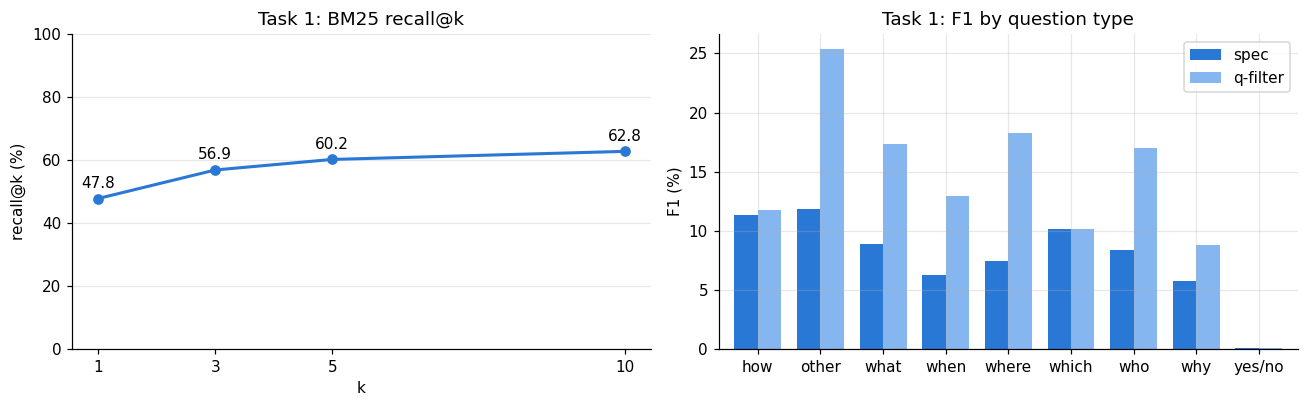

,question,gold,pred_spec,pred_qfilter
0,Was Abraham Lincoln the sixteenth President of...,yes,"the March 4, 1861, inauguration","the March 4, 1861, inauguration"
1,Did Lincoln sign the National Banking Act of 1...,yes,the sealed envelope,the sealed envelope
2,Did his mother die of pneumonia?,no,a twenty-two-month pregnancy,a twenty-two-month pregnancy
3,How many long was Lincoln's formal education?,18 months,Lincoln's formal education,about 18 months
4,When did Lincoln begin his political career?,1832,the Illinois General Assembly,the Illinois General Assembly
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper curren...",The Legal Tender Act,the United States Note
6,Who suggested Lincoln grow a beard?,11-year-old Grace Bedell,11-year-old Grace Bedell,11-year-old Grace Bedell
7,When did the Gettysburg address argue that Ame...,1776,"November 19, 1863","November 19, 1863"


In [9]:
s_t1, em_t1, f1_t1 = qa_scores(pred_t1)
s_t1qf, em_t1qf, f1_t1qf = qa_scores(pred_t1_qf)
t1_table = pd.DataFrame({"BM25 + Extract (spec)": {**s_t1, **recall_bm25},
                         "BM25 + Extract (q-filter)": {**s_t1qf, **recall_bm25}}).T.round(2)
display(t1_table)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(K_LIST, [recall_bm25[f"R@{k}"] for k in K_LIST], marker="o", lw=2, color=C["BM25"])
for k in K_LIST:
    ax[0].annotate(f"{recall_bm25[f'R@{k}']:.1f}", (k, recall_bm25[f"R@{k}"]), textcoords="offset points", xytext=(0, 7), ha="center")
ax[0].set(title="Task 1: BM25 recall@k", xlabel="k", ylabel="recall@k (%)", xticks=K_LIST, ylim=(0, 100))
by_type = pd.DataFrame({"qtype": qa_df["qtype"], "spec": f1_t1 * 100, "q-filter": f1_t1qf * 100}).groupby("qtype").mean()
by_type.plot.bar(ax=ax[1], color=[C["BM25"], "#86b6ef"], rot=0, width=0.75)
ax[1].set(title="Task 1: F1 by question type", xlabel="", ylabel="F1 (%)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task1.png", bbox_inches="tight"); plt.show()

pd.DataFrame({"question": QUESTIONS, "gold": ANSWERS, "pred_spec": pred_t1, "pred_qfilter": pred_t1_qf}).head(8)

**Note.** The extractive reader can never output *yes* / *no*, so it scores 0 on the yes/no questions by construction; the `(span)` columns show performance on questions whose answer can be a text span. The *q-filter* variant (drop candidate spans already contained in the question) is a one-line tweak, kept separate so the spec-exact baseline is still reported.

## Task 2 — Paper Reproduction: Retrieval-Augmented Generation (Lewis et al., 2020)

1. Dense retriever: `sentence-transformers/all-MiniLM-L6-v2`, L2-normalised embeddings in a FAISS `IndexFlatIP` (inner product on unit vectors = cosine similarity), over the **same passage index** as Task 1.
2. Generator: `Qwen/Qwen2.5-3B-Instruct`, prompted with the top-5 passages (each truncated to 200 tokens) + the question; greedy decoding (temperature = 0), max new tokens = 64.
3. Evaluate EM/F1 and recall@k. A closed-book run (same LLM, no passages) is added as a reference to show how much retrieval adds.

*Difference from the paper:* RAG fine-tunes a DPR retriever and a BART generator end to end; here both are frozen, off-the-shelf models (as the project specifies).

### 2.1 Dense retrieval

In [10]:
t0 = time.time()
encoder = SentenceTransformer(DENSE_MODEL, device=DEVICE)
P_EMB = encoder.encode(PASSAGES, batch_size=128, normalize_embeddings=True, show_progress_bar=True, convert_to_numpy=True).astype("float32")
Q_EMB = encoder.encode(QUESTIONS, batch_size=128, normalize_embeddings=True, convert_to_numpy=True).astype("float32")
index = faiss.IndexFlatIP(P_EMB.shape[1])
index.add(P_EMB)
_, dense_ids = index.search(Q_EMB, DEPTH)
dense_ranked = dense_ids.tolist()
print(f"dense encode + search: {time.time() - t0:.1f}s | dim={P_EMB.shape[1]}")
recall_dense = recall_at_k(dense_ranked)
recall_dense

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

dense encode + search: 13.6s | dim=384


{'R@1': np.float64(39.76377952755906),
 'R@3': np.float64(52.75590551181102),
 'R@5': np.float64(58.85826771653543),
 'R@10': np.float64(63.188976377952756)}

### 2.2 LLM generator

In [11]:
tok = AutoTokenizer.from_pretrained(LLM_NAME)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32,
                                           device_map="auto" if DEVICE == "cuda" else None)
llm.eval()

SYSTEM_RAG = ("You answer questions using the given passages. Reply with only the answer: a short phrase, "
              "name, number, date, or yes/no. Do not explain.")
SYSTEM_CB = ("You answer questions. Reply with only the answer: a short phrase, name, number, date, or yes/no. "
             "Do not explain.")

def truncate(text, n=MAX_PASSAGE_TOKENS):
    ids = tok(text, add_special_tokens=False)["input_ids"][:n]
    return tok.decode(ids)

def build_prompt(question, pids=None):
    if pids is None:
        msgs = [{"role": "system", "content": SYSTEM_CB}, {"role": "user", "content": f"Question: {question}\nAnswer:"}]
    else:
        ctx = "\n\n".join(f"[{j + 1}] {truncate(PASSAGES[p])}" for j, p in enumerate(pids))
        msgs = [{"role": "system", "content": SYSTEM_RAG},
                {"role": "user", "content": f"Passages:\n{ctx}\n\nQuestion: {question}\nAnswer:"}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def clean(ans):
    ans = ans.strip().split("\n")[0].strip()
    ans = re.sub(r"^(answer\s*:\s*)", "", ans, flags=re.I).strip()
    first = re.sub(r"[^\w]", "", ans.split()[0].lower()) if ans else ""
    if first in {"yes", "no"}:
        return first    # "Yes, he was" -> "yes"
    return ans.rstrip(".").strip()

@torch.no_grad()
def generate(prompts, desc=""):
    order = np.argsort([-len(p) for p in prompts])    # length-sorted batches = less padding
    outs = [None] * len(prompts)
    t0 = time.time()
    for b in range(0, len(prompts), GEN_BATCH):
        idx = order[b: b + GEN_BATCH]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True).to(llm.device)
        gen = llm.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None,
                           top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
        texts = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for i, t in zip(idx, texts):
            outs[i] = clean(t)
    print(f"{desc}: {len(prompts)} answers in {time.time() - t0:.0f}s")
    return outs

def rag_answers(name, ranked):
    # cached to disk so re-runs skip generation
    path = f"{OUT_DIR}/pred_{name}.json"
    if os.path.exists(path):
        cached = json.load(open(path))
        if cached.get("questions") == QUESTIONS:
            return cached["preds"]
    prompts = [build_prompt(q, None if ranked is None else r[:TOP_K]) for q, r in zip(QUESTIONS, ranked or [None] * len(QUESTIONS))]
    preds = generate(prompts, name)
    json.dump({"questions": QUESTIONS, "preds": preds}, open(path, "w"))
    return preds

print(build_prompt(QUESTIONS[0], dense_ranked[0][:TOP_K])[:1200], "...")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

<|im_start|>system
You answer questions using the given passages. Reply with only the answer: a short phrase, name, number, date, or yes/no. Do not explain.<|im_end|>
<|im_start|>user
Passages:
[1] Young Abraham Lincoln

[2] Abraham Lincoln (February 12, 1809 â April 15, 1865) was the sixteenth President of the United States, serving from March 4, 1861 until his assassination. As an outspoken opponent of the expansion of slavery in the United States, "[I]n his short autobiography written for the 1860 presidential campaign, Lincoln would describe his protest in the Illinois legislature as one that 'briefly defined his position on the slavery question, and so far as it goes, it was then the same that it is now." This was in reference to the anti-expansion sentiments he had then expressed. Doris Kearns Goodwin, Team of Rivals: The Political Genius of Abraham Lincoln (2005) p. 91.  Holzer pg. 232.  Writing of the Cooper Union  speech, Holzer notes, "Cooper Union proved a unique

[3] Sixt

In [12]:
set_seed()
pred_t2 = rag_answers("dense_llm", dense_ranked)
pred_cb = rag_answers("closed_book", None)

dense_llm: 918 answers in 233s
closed_book: 918 answers in 59s


### 2.3 Task 2 evaluation

,EM,F1,EM (span),F1 (span),EM (yes/no),R@1,R@3,R@5,R@10
Closed-book LLM (reference),25.49,30.77,5.12,14.65,50.73,NaN,NaN,NaN,NaN
Dense + LLM (RAG),54.47,64.30,30.51,48.29,84.15,39.76,52.76,58.86,63.19


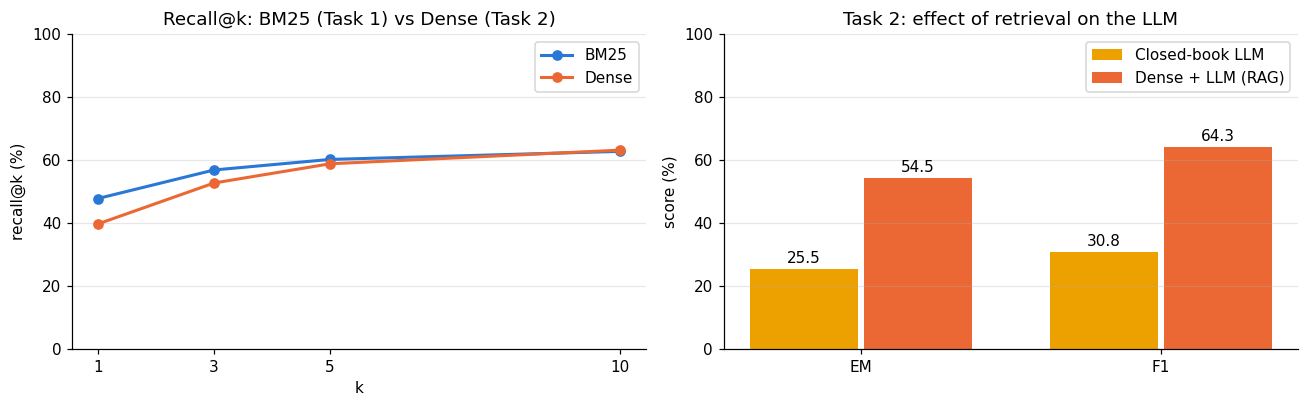

,question,gold,rag,closed_book
0,Was Abraham Lincoln the sixteenth President of...,yes,yes,yes
1,Did Lincoln sign the National Banking Act of 1...,yes,no,no
2,Did his mother die of pneumonia?,no,no,no
3,How many long was Lincoln's formal education?,18 months,18 months,Less than 1 year
4,When did Lincoln begin his political career?,1832,1832,1834
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper curren...",United States Note,Legal tender status for certain US government ...
6,Who suggested Lincoln grow a beard?,11-year-old Grace Bedell,Grace Bedell,Abraham Lincoln
7,When did the Gettysburg address argue that Ame...,1776,1776,1863


In [13]:
s_t2, em_t2, f1_t2 = qa_scores(pred_t2)
s_cb, em_cb, f1_cb = qa_scores(pred_cb)
t2_table = pd.DataFrame({"Closed-book LLM (reference)": s_cb,
                         "Dense + LLM (RAG)": {**s_t2, **recall_dense}}).T.round(2)
display(t2_table)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, rec in [("BM25", recall_bm25), ("Dense", recall_dense)]:
    ax[0].plot(K_LIST, [rec[f"R@{k}"] for k in K_LIST], marker="o", lw=2, color=C[name], label=name)
ax[0].set(title="Recall@k: BM25 (Task 1) vs Dense (Task 2)", xlabel="k", ylabel="recall@k (%)", xticks=K_LIST, ylim=(0, 100))
ax[0].legend()
names = ["Closed-book", "Dense"]
vals = [[s_cb["EM"], s_cb["F1"]], [s_t2["EM"], s_t2["F1"]]]
x = np.arange(2)
for j, (n, v) in enumerate(zip(names, vals)):
    bars = ax[1].bar(x + (j - 0.5) * 0.38, v, 0.36, color=C[n], label="Closed-book LLM" if n == "Closed-book" else "Dense + LLM (RAG)")
    ax[1].bar_label(bars, fmt="%.1f", padding=2)
ax[1].set(title="Task 2: effect of retrieval on the LLM", xticks=x, xticklabels=["EM", "F1"], ylabel="score (%)", ylim=(0, 100))
ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task2.png", bbox_inches="tight"); plt.show()

pd.DataFrame({"question": QUESTIONS, "gold": ANSWERS, "rag": pred_t2, "closed_book": pred_cb}).head(8)

## Task 3 — Combine & Improve: Hybrid Retrieval with Groundedness Verification

1. Fuse BM25 (Task 1) and dense (Task 2) rankings with **Reciprocal Rank Fusion**: score(d) = Σ_r 1 / (60 + rank_r(d)), over the top-100 of each retriever.
2. Compare all three retrievers under the same readers (extractive and LLM), so differences come from retrieval only.
3. Groundedness check: for each generated answer, lexical overlap = fraction of the answer's content words that appear in its retrieved passages. Answers with overlap < τ = 0.5 are flagged as likely ungrounded (or abstained on).
4. Report how often correct answers have high overlap and incorrect answers have low overlap.

### 3.1 Reciprocal Rank Fusion

,R@1,R@3,R@5,R@10
BM25,47.83,56.89,60.24,62.80
Dense,39.76,52.76,58.86,63.19
Hybrid (RRF),47.24,57.68,61.42,66.14


Top-5 answer hits (span questions):
 both          272
BM25 only      34
Dense only     27
neither       175
Hybrid recovers 37 of 61 questions found by only one retriever


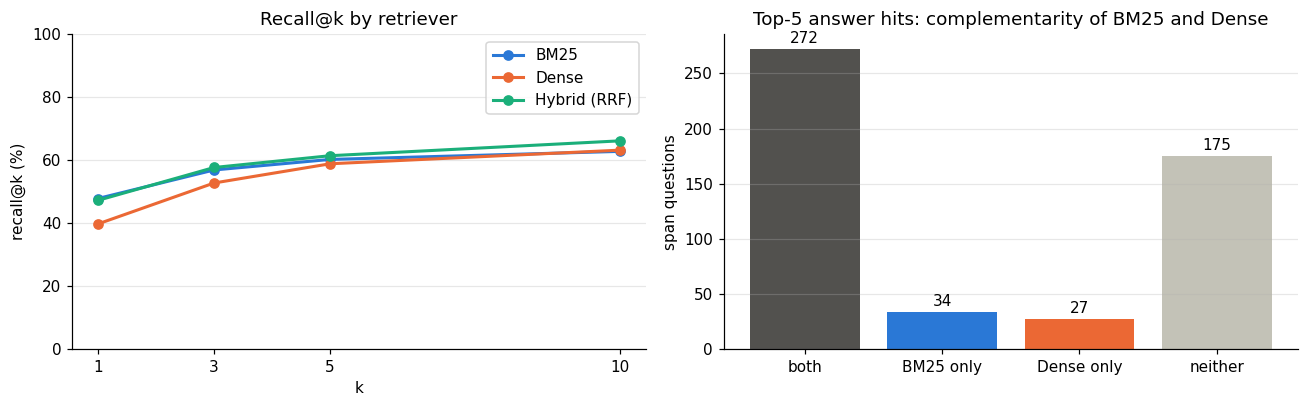

In [14]:
def rrf(rankings, c=RRF_C, depth=DEPTH):
    fused = []
    for lists in zip(*rankings):
        score = collections.defaultdict(float)
        for lst in lists:
            for rank, pid in enumerate(lst[:depth], start=1):
                score[pid] += 1.0 / (c + rank)
        fused.append([p for p, _ in sorted(score.items(), key=lambda x: (-x[1], x[0]))][:depth])
    return fused

hybrid_ranked = rrf([bm25_ranked, dense_ranked])
recall_hybrid = recall_at_k(hybrid_ranked)
recall_tbl = pd.DataFrame({"BM25": recall_bm25, "Dense": recall_dense, "Hybrid (RRF)": recall_hybrid}).T.round(2)
display(recall_tbl)

# where does each retriever find the answer in top-5 (span questions)
hit = lambda ranked: np.array([any(answer_in_passage(ANSWERS[i], PASSAGES[p]) for p in ranked[i][:TOP_K]) for i in range(len(QUESTIONS))])[SPAN_MASK]
h_b, h_d, h_h = hit(bm25_ranked), hit(dense_ranked), hit(hybrid_ranked)
overlap_counts = pd.Series({"both": (h_b & h_d).sum(), "BM25 only": (h_b & ~h_d).sum(),
                            "Dense only": (~h_b & h_d).sum(), "neither": (~h_b & ~h_d).sum()})
print("Top-5 answer hits (span questions):\n", overlap_counts.to_string())
print(f"Hybrid recovers {(h_h & (h_b ^ h_d)).sum()} of {(h_b ^ h_d).sum()} questions found by only one retriever")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, rec in [("BM25", recall_bm25), ("Dense", recall_dense), ("Hybrid (RRF)", recall_hybrid)]:
    ax[0].plot(K_LIST, [rec[f"R@{k}"] for k in K_LIST], marker="o", lw=2, color=C[name], label=name)
ax[0].set(title="Recall@k by retriever", xlabel="k", ylabel="recall@k (%)", xticks=K_LIST, ylim=(0, 100))
ax[0].legend()
bars = ax[1].bar(overlap_counts.index, overlap_counts.values, color=["#52514e", C["BM25"], C["Dense"], "#c3c2b7"])
ax[1].bar_label(bars, padding=2)
ax[1].set(title="Top-5 answer hits: complementarity of BM25 and Dense", ylabel="span questions")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task3_recall.png", bbox_inches="tight"); plt.show()

### 3.2 End-to-end QA: every retriever × every reader

bm25_llm: 918 answers in 266s
hybrid_llm: 918 answers in 255s


,retriever,reader,EM,F1,EM (span),F1 (span),EM (yes/no),R@1,R@3,R@5,R@10
0,BM25,Extractive,5.01,9.21,9.06,16.55,0.00,47.83,56.89,60.24,62.80
1,Dense,Extractive,4.47,7.98,8.07,14.32,0.00,39.76,52.76,58.86,63.19
2,Hybrid (RRF),Extractive,4.47,9.08,8.07,16.31,0.00,47.24,57.68,61.42,66.14
3,BM25,LLM,54.79,65.20,31.30,50.11,83.90,47.83,56.89,60.24,62.80
4,Dense,LLM,54.47,64.30,30.51,48.29,84.15,39.76,52.76,58.86,63.19
5,Hybrid (RRF),LLM,55.99,66.02,31.89,50.01,85.85,47.24,57.68,61.42,66.14


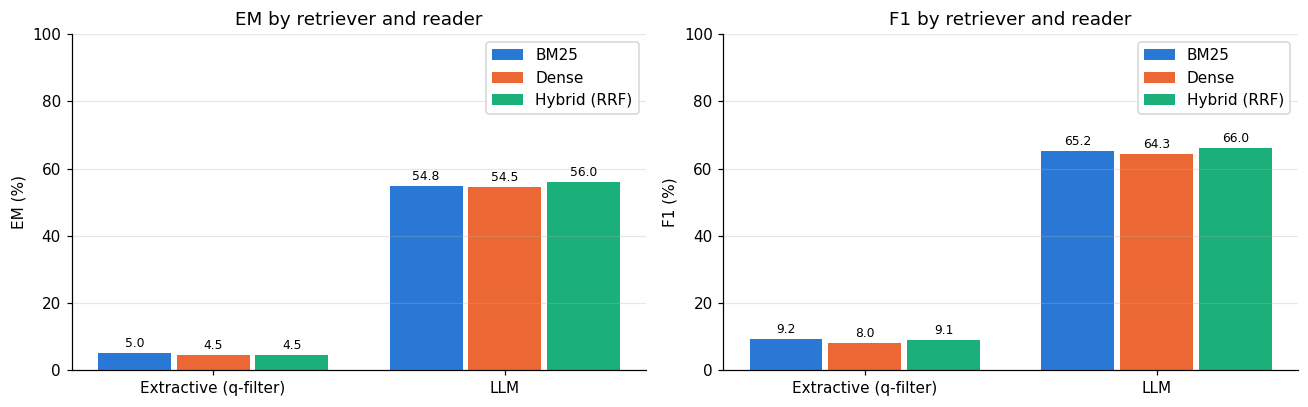

In [15]:
set_seed()
pred_bm25_llm = rag_answers("bm25_llm", bm25_ranked)
pred_hyb_llm = rag_answers("hybrid_llm", hybrid_ranked)
pred_dense_ext = run_extractive(dense_ranked, q_filter=True)
pred_hyb_ext = run_extractive(hybrid_ranked, q_filter=True)

systems = {
    ("BM25", "Extractive"): pred_t1_qf, ("Dense", "Extractive"): pred_dense_ext, ("Hybrid (RRF)", "Extractive"): pred_hyb_ext,
    ("BM25", "LLM"): pred_bm25_llm, ("Dense", "LLM"): pred_t2, ("Hybrid (RRF)", "LLM"): pred_hyb_llm,
}
recalls = {"BM25": recall_bm25, "Dense": recall_dense, "Hybrid (RRF)": recall_hybrid}
rows, per_q_f1 = [], {}
for (ret, rdr), preds in systems.items():
    s, em, f1 = qa_scores(preds)
    per_q_f1[(ret, rdr)] = f1
    rows.append({"retriever": ret, "reader": rdr, **s, **recalls[ret]})
grid = pd.DataFrame(rows).round(2)
display(grid)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, metric in zip(ax, ["EM", "F1"]):
    x = np.arange(2)
    for j, ret in enumerate(["BM25", "Dense", "Hybrid (RRF)"]):
        v = grid[grid.retriever == ret].set_index("reader").loc[["Extractive", "LLM"], metric].values
        bars = a.bar(x + (j - 1) * 0.27, v, 0.25, color=C[ret], label=ret)
        a.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    a.set(title=f"{metric} by retriever and reader", xticks=x, xticklabels=["Extractive (q-filter)", "LLM"], ylabel=f"{metric} (%)", ylim=(0, 100))
    a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task3_grid.png", bbox_inches="tight"); plt.show()

### 3.3 Groundedness verification (lexical overlap of answer with retrieved evidence)

In [16]:
def overlap_score(answer, pids):
    # share of the answer's content words found in the retrieved passages
    a = tokenize(answer) or re.findall(r"\w+", answer.lower())
    if not a:
        return 0.0
    ev = set(re.findall(r"\w+", " ".join(PASSAGES[p] for p in pids).lower()))
    return float(np.mean([t in ev for t in a]))

def groundedness_report(preds, ranked, f1s, tau=GROUND_TAU):
    ov = np.array([overlap_score(p, r[:TOP_K]) for p, r in zip(preds, ranked)])
    yn = np.array([is_yes_no(p) for p in preds])        # yes/no answers cannot be checked lexically
    correct = f1s >= CORRECT_F1
    m = ~yn
    high = ov >= tau
    rep = {"answers checked": int(m.sum()), "yes/no answers (not checkable)": int(yn.sum()),
           "% correct with high overlap": 100 * high[m & correct].mean(),
           "% incorrect with low overlap": 100 * (~high)[m & ~correct].mean(),
           "groundedness-check accuracy": 100 * (high == correct)[m].mean(),
           "% answers flagged": 100 * (~high)[m].mean(),
           "accuracy of kept answers": 100 * correct[m & high].mean(),
           "accuracy of flagged answers": 100 * correct[m & ~high].mean() if (m & ~high).any() else np.nan}
    return rep, ov, correct, m

g_t2, ov_t2, cor_t2, m_t2 = groundedness_report(pred_t2, dense_ranked, f1_t2)
g_hyb, ov_hyb, cor_hyb, m_hyb = groundedness_report(pred_hyb_llm, hybrid_ranked, per_q_f1[("Hybrid (RRF)", "LLM")])
g_cb, *_ = groundedness_report(pred_cb, dense_ranked, f1_cb)   # closed-book answers vs dense evidence
g_table = pd.DataFrame({"Dense + LLM (Task 2)": g_t2, "Hybrid + LLM (Task 3)": g_hyb,
                        "Closed-book LLM vs dense evidence": g_cb}).T.round(2)
display(g_table)

,answers checked,yes/no answers (not checkable),% correct with high overlap,% incorrect with low overlap,groundedness-check accuracy,% answers flagged,accuracy of kept answers,accuracy of flagged answers
Dense + LLM (Task 2),467.0,451.0,99.61,10.43,59.31,4.93,57.43,4.35
Hybrid + LLM (Task 3),482.0,436.0,98.86,13.30,60.17,6.64,58.00,9.38
Closed-book LLM vs dense evidence,471.0,447.0,91.04,59.65,64.12,52.44,27.23,2.43


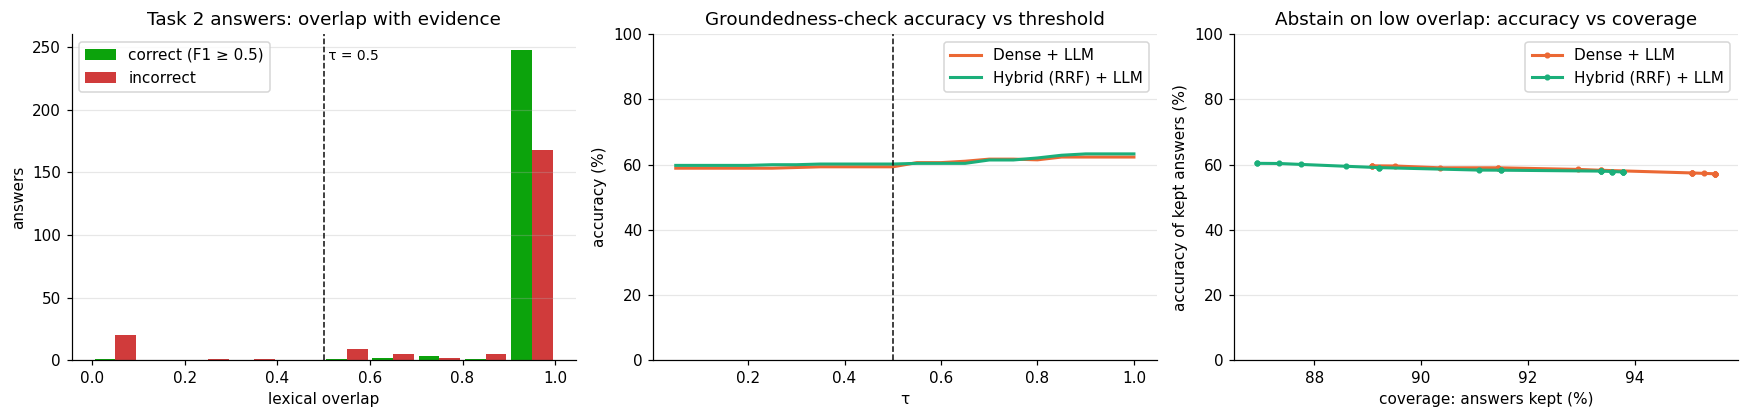

Flagged (low overlap):


,question,gold,pred,overlap,correct
24,What trail did Lincoln use a Farmers' Almanac in?,"he defended William ""Duff"" Armstrong",None,0.0,False
64,What are the similarities between beetles and ...,mouthparts,None,0.0,False
112,What years were Coolidge's two sons born in?,1906 and 1908,"1899, 1900",0.0,False
125,How many provinces and territories does Canada...,A federation now comprising ten provinces and ...,13,0.0,False
224,What body of water lies to the south of Finland?,the Gulf of Finland,Baltic Sea,0.0,False
290,What European countries established states in ...,The UK,"Britain, Portugal",0.0,False


Incorrect but high overlap (passes the check):


,question,gold,pred,overlap,correct
5,What did The Legal Tender Act of 1862 establish?,"the United States Note, the first paper curren...",United States Note,1.0,False
17,Why did Lincoln issue the Emancipation Proclam...,To free slaves,To weaken the rebellion controlled by slave ow...,1.0,False
21,How old was Lincoln in 1816?,seven,Nine,1.0,False
23,How long was Lincoln's legal Career?,23 years,23-years,1.0,False
28,Who graduated in ecclesiastical law at the ear...,Amedeo Avogadro,He,1.0,False
30,When did he become a professor?,1820,1833,1.0,False


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
bins = np.linspace(0, 1, 11)
ax[0].hist([ov_t2[m_t2 & cor_t2], ov_t2[m_t2 & ~cor_t2]], bins=bins, color=[C["correct"], C["incorrect"]],
           label=[f"correct (F1 ≥ {CORRECT_F1})", "incorrect"], rwidth=0.9)
ax[0].axvline(GROUND_TAU, color="#0b0b0b", ls="--", lw=1)
ax[0].text(GROUND_TAU, ax[0].get_ylim()[1] * 0.92, f" τ = {GROUND_TAU}", fontsize=9)
ax[0].set(title="Task 2 answers: overlap with evidence", xlabel="lexical overlap", ylabel="answers")
ax[0].legend()

taus = np.linspace(0.05, 1.0, 20)
for name, ov, cor, m in [("Dense", ov_t2, cor_t2, m_t2), ("Hybrid (RRF)", ov_hyb, cor_hyb, m_hyb)]:
    acc = [100 * ((ov >= t) == cor)[m].mean() for t in taus]
    ax[1].plot(taus, acc, lw=2, color=C[name], label=f"{name} + LLM")
ax[1].axvline(GROUND_TAU, color="#0b0b0b", ls="--", lw=1)
ax[1].set(title="Groundedness-check accuracy vs threshold", xlabel="τ", ylabel="accuracy (%)", ylim=(0, 100))
ax[1].legend()

for name, ov, cor, m in [("Dense", ov_t2, cor_t2, m_t2), ("Hybrid (RRF)", ov_hyb, cor_hyb, m_hyb)]:
    cov = [100 * (ov >= t)[m].mean() for t in taus]
    sel = [100 * cor[m & (ov >= t)].mean() if (m & (ov >= t)).any() else np.nan for t in taus]
    ax[2].plot(cov, sel, marker="o", ms=3, lw=2, color=C[name], label=f"{name} + LLM")
ax[2].set(title="Abstain on low overlap: accuracy vs coverage", xlabel="coverage: answers kept (%)",
          ylabel="accuracy of kept answers (%)", ylim=(0, 100))
ax[2].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/task3_groundedness.png", bbox_inches="tight"); plt.show()

# examples: wrong but high overlap vs right but low overlap
ex = pd.DataFrame({"question": QUESTIONS, "gold": ANSWERS, "pred": pred_t2, "overlap": ov_t2.round(2), "correct": cor_t2})[m_t2]
print("Flagged (low overlap):"); display(ex[ex.overlap < GROUND_TAU].head(6))
print("Incorrect but high overlap (passes the check):"); display(ex[(ex.overlap >= GROUND_TAU) & ~ex.correct].head(6))

## Results & Conclusions

,system,EM,F1,EM (span),F1 (span),EM (yes/no),R@1,R@3,R@5,R@10
0,BM25 + Extractive (spec) [Task 1],1.96,5.04,3.54,9.02,0.00,47.83,56.89,60.24,62.80
1,BM25 + Extractive (q-filter),5.01,9.21,9.06,16.55,0.00,47.83,56.89,60.24,62.80
2,Dense + Extractive,4.47,7.98,8.07,14.32,0.00,39.76,52.76,58.86,63.19
3,Hybrid (RRF) + Extractive,4.47,9.08,8.07,16.31,0.00,47.24,57.68,61.42,66.14
4,BM25 + LLM,54.79,65.20,31.30,50.11,83.90,47.83,56.89,60.24,62.80
5,Dense + LLM [Task 2],54.47,64.30,30.51,48.29,84.15,39.76,52.76,58.86,63.19
6,Hybrid (RRF) + LLM [Task 3],55.99,66.02,31.89,50.01,85.85,47.24,57.68,61.42,66.14
7,Closed-book LLM [ref],25.49,30.77,5.12,14.65,50.73,NaN,NaN,NaN,NaN


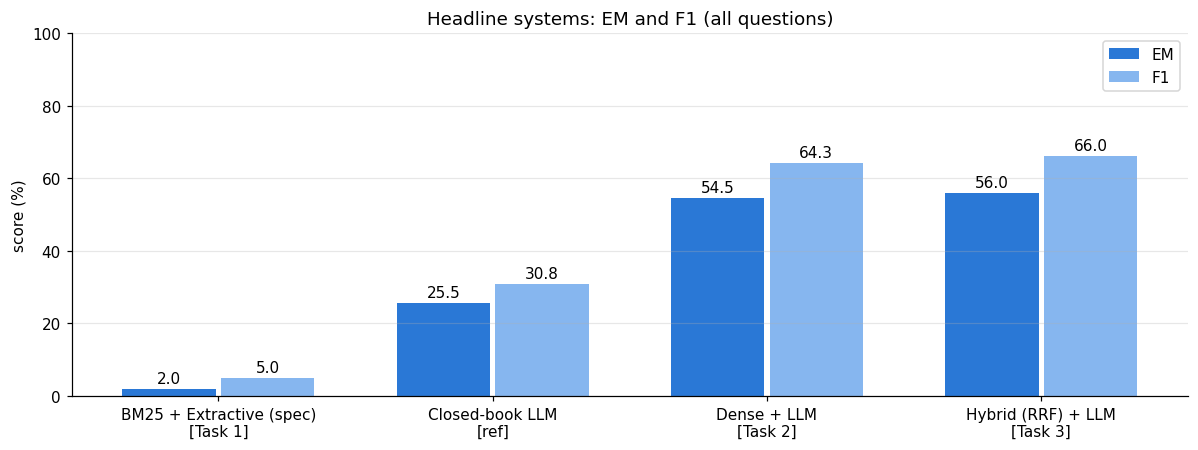

All tables, predictions and figures written to /content/results


In [18]:
summary = grid.copy()
summary.insert(0, "system", summary.retriever + " + " + summary.reader)
summary.loc[(summary.retriever == "BM25") & (summary.reader == "Extractive"), "system"] += " (q-filter)"
spec_row = {"system": "BM25 + Extractive (spec) [Task 1]", "retriever": "BM25", "reader": "Extractive", **s_t1, **recall_bm25}
cb_row = {"system": "Closed-book LLM [ref]", "retriever": "-", "reader": "LLM", **s_cb}
summary = pd.concat([pd.DataFrame([spec_row]), summary, pd.DataFrame([cb_row])], ignore_index=True).round(2)
summary.loc[summary.system == "Dense + LLM", "system"] += " [Task 2]"
summary.loc[summary.system == "Hybrid (RRF) + LLM", "system"] += " [Task 3]"
summary = summary.drop(columns=["retriever", "reader"])
summary.to_csv(f"{OUT_DIR}/metrics_summary.csv", index=False)
g_table.to_csv(f"{OUT_DIR}/groundedness.csv")
pd.DataFrame({"question": QUESTIONS, "gold": ANSWERS, "qtype": qa_df["qtype"], "t1_spec": pred_t1, "t1_qfilter": pred_t1_qf,
              "t2_dense_llm": pred_t2, "t3_hybrid_llm": pred_hyb_llm, "closed_book": pred_cb,
              "t2_overlap": ov_t2, "t3_overlap": ov_hyb}).to_csv(f"{OUT_DIR}/predictions.csv", index=False)
display(summary)

fig, ax = plt.subplots(figsize=(11, 4.2))
sys_names = ["BM25 + Extractive (spec) [Task 1]", "Closed-book LLM [ref]", "Dense + LLM [Task 2]", "Hybrid (RRF) + LLM [Task 3]"]
sub = summary.set_index("system").loc[sys_names]
x = np.arange(len(sys_names))
for j, (metric, col) in enumerate([("EM", "#2a78d6"), ("F1", "#86b6ef")]):
    bars = ax.bar(x + (j - 0.5) * 0.36, sub[metric], 0.34, color=col, label=metric)
    ax.bar_label(bars, fmt="%.1f", padding=2)
ax.set(title="Headline systems: EM and F1 (all questions)", xticks=x, xticklabels=[s.replace(" [", "\n[") for s in sys_names],
       ylabel="score (%)", ylim=(0, 100))
ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/summary.png", bbox_inches="tight"); plt.show()
print("All tables, predictions and figures written to", os.path.abspath(OUT_DIR))

In [19]:
# data-driven key findings (numbers come from this run)
best_r5 = recall_tbl["R@5"].idxmax()
print(f"1. Retrieval: R@5 BM25 = {recall_bm25['R@5']:.1f}, Dense = {recall_dense['R@5']:.1f}, Hybrid = {recall_hybrid['R@5']:.1f} -> best: {best_r5}.")
print(f"   {(h_b ^ h_d).sum()} span questions are answered in top-5 by only one retriever; RRF keeps {(h_h & (h_b ^ h_d)).sum()} of them.")
print(f"2. Reading: Task 1 extractive EM/F1 = {s_t1['EM']:.1f}/{s_t1['F1']:.1f}; Task 2 RAG EM/F1 = {s_t2['EM']:.1f}/{s_t2['F1']:.1f}; "
      f"Task 3 hybrid RAG EM/F1 = {qa_scores(pred_hyb_llm)[0]['EM']:.1f}/{qa_scores(pred_hyb_llm)[0]['F1']:.1f}.")
print(f"3. Retrieval vs memory: closed-book EM = {s_cb['EM']:.1f}, so retrieval adds {s_t2['EM'] - s_cb['EM']:+.1f} EM points.")
print(f"4. Groundedness (Task 2, τ = {GROUND_TAU}): {g_t2['% correct with high overlap']:.1f}% of correct answers have high overlap, "
      f"{g_t2['% incorrect with low overlap']:.1f}% of incorrect answers have low overlap; check accuracy = {g_t2['groundedness-check accuracy']:.1f}%.")
print(f"   Kept answers are correct {g_t2['accuracy of kept answers']:.1f}% of the time vs {g_t2['accuracy of flagged answers']:.1f}% for flagged ones.")

1. Retrieval: R@5 BM25 = 60.2, Dense = 58.9, Hybrid = 61.4 -> best: Hybrid (RRF).
   61 span questions are answered in top-5 by only one retriever; RRF keeps 37 of them.
2. Reading: Task 1 extractive EM/F1 = 2.0/5.0; Task 2 RAG EM/F1 = 54.5/64.3; Task 3 hybrid RAG EM/F1 = 56.0/66.0.
3. Retrieval vs memory: closed-book EM = 25.5, so retrieval adds +29.0 EM points.
4. Groundedness (Task 2, τ = 0.5): 99.6% of correct answers have high overlap, 10.4% of incorrect answers have low overlap; check accuracy = 59.3%.
   Kept answers are correct 57.4% of the time vs 4.3% for flagged ones.


### Discussion

All numbers below come from the run above (918 questions: 508 with span answers, 410 yes/no; seed 42, greedy decoding).

**Headline results**

| System | EM | F1 | R@1 | R@5 | R@10 |
|---|---|---|---|---|---|
| Task 1: BM25 + Extractive (spec) | 1.96 | 5.04 | 47.83 | 60.24 | 62.80 |
| Task 1 variant: BM25 + Extractive (q-filter) | 5.01 | 9.21 | 47.83 | 60.24 | 62.80 |
| Closed-book LLM (reference, no retrieval) | 25.49 | 30.77 | – | – | – |
| Task 2: Dense + LLM (RAG) | 54.47 | 64.30 | 39.76 | 58.86 | 63.19 |
| BM25 + LLM (control) | 54.79 | 65.20 | 47.83 | 60.24 | 62.80 |
| **Task 3: Hybrid (RRF) + LLM** | **55.99** | **66.02** | 47.24 | **61.42** | **66.14** |

**1. Retrieval: BM25 vs dense vs hybrid**
- BM25 beats the dense retriever at the top of the ranking (R@1 47.8 vs 39.8). Questions in this dataset reuse rare words from the passage (names, dates, technical terms), which is exactly what BM25 rewards. A small general-purpose encoder (MiniLM, 384-dim, not trained on this data) loses some of that exact-word precision.
- Dense catches up by k = 10 (63.2 vs 62.8), so it finds relevant passages but ranks them lower.
- The two retrievers fail on different questions: 34 span questions are found in the top-5 only by BM25 and 27 only by dense. RRF keeps 37 of these 61 and gives the best recall at k = 3, 5, 10 (R@10 66.1, about +3 points over either retriever alone). At k = 1 it is level with BM25 (47.2 vs 47.8): fusion helps most when the reader sees several passages.
- Recall flattens out near 63–66%. 175 of 508 span questions (34%) have no exact answer-string match in the top-5 from either retriever. Part of this is a measurement limit, not a retrieval failure: many gold answers are long phrases or sentences (e.g. "the United States Note, the first paper currency…") that never appear word for word in any passage.

**2. Reading: extraction vs generation**
- The spec extractive reader is very weak (EM 1.96). The "longest noun phrase" rule often returns the subject of the question itself (e.g. "Lincoln's formal education" instead of "18 months"). Dropping spans already in the question (q-filter) raises EM 2.6× (5.0) and span-F1 from 9.0 to 16.6, but the approach stays limited.
- It also scores 0 on the 410 yes/no questions (45% of the dataset) by construction, which caps overall EM far below the LLM.
- The reader, not retrieval, is the bottleneck for Task 1: the answer is in the top-1 passage for 47.8% of span questions, but only 9.1% of span questions get an exact-match answer, so most of the time the right passage is found and the wrong span is picked. This is also why better retrieval (dense / hybrid) does not help the extractive reader – it only reads the top-1 passage, where hybrid is no better than BM25.
- The LLM reader is about 10× better (EM 54–56). Comparing with the closed-book run isolates the value of retrieval: +29 EM overall, and on yes/no questions closed-book is at chance level (50.7%) while RAG reaches 84.2%.
- Span EM (≈31) is much lower than span F1 (≈48–50). Many "wrong" answers are partly right, e.g. "Grace Bedell" vs gold "11-year-old Grace Bedell", or "23-years" vs "23 years". EM understates the LLM; F1 is the fairer reader metric.

**3. Hybrid retrieval end to end (Task 3)**
- With the same LLM reader, hybrid gives the best scores: EM 55.99 / F1 66.02, vs 54.47 / 64.30 for dense (Task 2) and 54.79 / 65.20 for BM25.
- The gain is real but small: +1.5 EM over dense is about 14 questions out of 918. With a single run and no significance test, this should be read as "hybrid is at least as good as either retriever, and slightly better", not as a large improvement.
- Interesting point: BM25 + LLM matches or slightly beats the Task 2 dense RAG, so on this Wikipedia-style dataset the lexical retriever is a strong baseline.

**4. Groundedness check (lexical overlap, τ = 0.5)**
- Checked: the 467 non-yes/no Task 2 answers (yes/no answers never appear word for word in evidence, so they cannot be checked this way).
- 99.6% of correct answers have high overlap, so the check almost never rejects a good answer.
- But only 10.4% of incorrect answers have low overlap. Most RAG errors are **grounded but wrong**: the model copies a real span from a retrieved passage, just the wrong one (e.g. "1833" instead of "1820", "He" as a person's name). Lexical overlap cannot catch this kind of error.
- When the check does flag an answer, it is almost always right: 22 of 23 flagged answers (95.7%) were incorrect. Typical flagged outputs are "None" (the model found nothing) or numbers/names not in the passages (e.g. "1899, 1900" for "1906 and 1908").
- Abstaining on flagged answers keeps 95% of answers and raises their accuracy from 54.8% to 57.4%.
- The overall check accuracy (59.3%) is only a little above the share of correct answers (54.8%) and hides this one-sided behaviour; flag precision and the per-class rates above are more informative.
- On closed-book answers the same check flags 59.7% of incorrect answers (vs 10.4% for RAG). This is the hallucination link with Project 7: lexical overlap is a good detector of answers made up from the model's memory, but a poor detector of retrieval mistakes once the model is already reading the evidence.

**5. Limitations**
- recall@k uses answer-string matching because the dataset has no gold passage IDs; it understates recall for long gold answers.
- The corpus has some noisy passages (title-only passages such as "Young Abraham Lincoln", and some encoding errors like "â"), which waste retrieval slots.
- τ = 0.5 and the correctness cut-off (F1 ≥ 0.5) were fixed before the run; the threshold sweep is analysis only. All results are from one run with one seed and one LLM (Qwen2.5-3B-Instruct).
- Both models are frozen; the original RAG paper trains the retriever and generator end to end, so absolute numbers are not comparable with the paper.